# Benchmarking figures

In [ ]:
import glob
import logging
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.ticker import NullFormatter
from matplotlib.lines import Line2D
from scipy import stats

SUMMARY_DIR = "benchmark_summary_tables"
SCALARS_FILE = os.path.join(SUMMARY_DIR, "summary_scalars.csv.gz")
POOLED_FILE = os.path.join(SUMMARY_DIR, "summary_pooled.csv.gz")
BENCHMARK_DIR = os.path.join(
    "..", "benchmarking", "const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer"
)
CHECKPOINT = "const_split_bott_zigzag_1s14__seq256_knn7w_rank3"
# The configurations of ARGNN whose prediction time comes from each folder of time_predictions.py.
ARGNN_POLEGON = "arggnn_polegon"
ARGNN_TSDATE = "arggnn_tsdate"
FINETUNED_SUFFIX = "_finetuned_ooa"
PREDICTION_TIMES = {
    os.path.join(BENCHMARK_DIR, CHECKPOINT, "prediction_times"): [ARGNN_POLEGON, ARGNN_TSDATE],
    os.path.join(BENCHMARK_DIR, f"{CHECKPOINT}_finetuned_ooa_10_epochs_lr_2e-4", "prediction_times"): [
        ARGNN_POLEGON + FINETUNED_SUFFIX,
        ARGNN_TSDATE + FINETUNED_SUFFIX,
    ],
}
# The figures go to figures/, at the text width of the paper (letter paper, 1-inch margins).
FIGURES_DIR = "figures"
FIGURE_WIDTH = 6.5
FIGURE_DPI = 500
# The matplotlib plotting style.
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "text.hinting": "no_hinting",
        "font.size": 8,
        "figure.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 8,
        "legend.frameon": False,
        "axes.formatter.useoffset": False,
        "pdf.fonttype": 42,
        "lines.linewidth": 1.3,
        "lines.markersize": 2.5,
    }
)
# Writing cmtt10, the font of the model names, into a PDF makes fontTools warn about the dates in the font file.
logging.getLogger("fontTools.ttLib.tables._h_e_a_d").setLevel(logging.ERROR)
# The demographic models, in the order of the figures, named as in the manuscript in cmtt10 (mathtext \mathtt).
MODELS = ["const", "split", "bott", "zigzag_1s14", "ooa"]
MODEL_LABEL = {
    model: r"$\mathtt{" + model.replace("_1s14", "") + "}$" for model in MODELS
}
SIZES = list(range(10, 101, 10))
TRAINING_SIZES = [10, 20, 50]
# The methods in the order of the legends, ARGNN first, then the others from fastest to slowest.
METHODS = {
    ARGNN_POLEGON: "ARGNN + POLEGON",
    ARGNN_TSDATE: "ARGNN + tsdate",
    "tsinfer_tsdate": "tsinfer + tsdate",
    "relate": "Relate",
    "singer_polegon": "SINGER + POLEGON",
}
REFERENCES = {
    "true_topology_polegon": "Simulated topology + POLEGON",
    "true_topology_tsdate": "Simulated topology + tsdate",
}
# The two datings of ARGNN share the same topology.
TOPOLOGY_METHODS = {
    ARGNN_POLEGON: "ARGNN",
    "tsinfer_tsdate": "tsinfer",
    "relate": "Relate",
    "singer_polegon": "SINGER",
}
# Okabe-Ito colors, with black for the references.
COLOR = {
    ARGNN_POLEGON: "#0072B2",
    ARGNN_TSDATE: "#56B4E9",
    "tsinfer_tsdate": "#E69F00",
    "relate": "#009E73",
    "singer_polegon": "#CC79A7",
    "true_topology_polegon": "#000000",
    "true_topology_tsdate": "#000000",
}
LINESTYLE = {"true_topology_polegon": ":", "true_topology_tsdate": "--"}
# The time grid of src/arg_metrics.py: tau_0 = 0, tau_b = 100 x 2000^((b - 1)/29) for b = 1 to 30, tau_31 = inf.
TAU = np.concatenate([[0.0], 100 * 2000.0 ** (np.arange(30) / 29), [np.inf]])
# M draws give a central interval whose expected coverage is gamma (M - 1)/(M + 1) under calibration.
DRAWS = 100

In [2]:
def read_prediction_seconds():
    """ARGNN's prediction time of every data set, from the tables of time_predictions.py, as rows of the
    scalars for the configurations of each folder."""
    parts = []
    for folder, configurations in PREDICTION_TIMES.items():
        paths = sorted(glob.glob(os.path.join(folder, "*", "*.csv")))
        times_df = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
        print(
            f"{folder}: {len(paths)} tables, {len(times_df)} data sets, "
            f"{int(times_df['identical_to_kept'].sum())} predictions identical to the scored ones, "
            f"{times_df['node'].nunique()} nodes"
        )
        times_df = times_df[["model", "size", "replicate", "wall_seconds_predict"]]
        for configuration in configurations:
            parts.append(
                times_df.rename(columns={"wall_seconds_predict": "value"}).assign(
                    configuration=configuration,
                    quantity="wall_seconds_predict",
                    pair_class="",
                )
            )
    return pd.concat(parts, ignore_index=True)


def read_tables():
    """The scalars and the pooled rows of benchmark_summary_tables.ipynb, with ARGNN's prediction times replaced by
    those of time_predictions.py."""
    # NaN is written as nan, so that the empty pair class stays an empty string.
    scalars_df = pd.read_csv(SCALARS_FILE, keep_default_na=False, na_values=["nan"])
    pooled_df = pd.read_csv(POOLED_FILE, keep_default_na=False, na_values=["nan"])
    # The prediction times of the first run are incomplete, so all of them are replaced.
    old = scalars_df["configuration"].str.startswith("arggnn") & (
        scalars_df["quantity"] == "wall_seconds_predict"
    )
    scalars_df = pd.concat(
        [scalars_df[~old], read_prediction_seconds()], ignore_index=True
    )
    return scalars_df, pooled_df


def values(scalars_df, quantity, configurations, pair_class=None):
    """One value per data set of a quantity for some configurations: model, size, replicate, configuration,
    value. pair_class is "all" for the metrics of pairs and "" for the others."""
    if pair_class is None:
        pair_class = "all" if quantity in ("RMSLE", "bias", "L2", "N") else ""
    rows = (
        (scalars_df["quantity"] == quantity)
        & scalars_df["configuration"].isin(configurations)
        & (scalars_df["pair_class"] == pair_class)
    )
    return scalars_df.loc[
        rows, ["model", "size", "replicate", "configuration", "value"]
    ].copy()


def mean_ci(values_df, keys):
    """Mean, 95% confidence interval half-width (1.96 SD / sqrt(n)), and n of value over the rows of each key."""
    grouped = values_df.groupby(keys)["value"]
    summary_df = grouped.agg(["mean", "std", "count"]).reset_index()
    summary_df["ci"] = 1.96 * summary_df["std"] / np.sqrt(summary_df["count"])
    return summary_df


def style_panel(axis, letter, title=None, title_size=8):
    """The bold panel letter and the title above the panel, as in the loss figures."""
    axis.annotate(
        letter,
        (0, 1),
        xycoords="axes fraction",
        xytext=(0, 6),
        textcoords="offset points",
        fontweight="bold",
        fontsize=9,
        ha="left",
        va="bottom",
    )
    if title:
        # The mathtext of a model name takes the Computer Modern fonts, so \mathtt is cmtt10.
        axis.annotate(
            title,
            (0, 1),
            xycoords="axes fraction",
            xytext=(11, 6),
            textcoords="offset points",
            ha="left",
            va="bottom",
            fontsize=title_size,
            math_fontfamily="cm",
        )


def save(figure, name):
    """Write a figure to FIGURES_DIR as a PDF file."""
    path = os.path.join(FIGURES_DIR, f"{name}.pdf")
    figure.savefig(path, dpi=FIGURE_DPI)
    print("written:", path)


def paired(values_df, first, second):
    """The data sets with a value for both configurations, as columns first and second."""
    wide_df = values_df.pivot_table(
        index=["model", "size", "replicate"], columns="configuration", values="value"
    )
    return wide_df[[first, second]].dropna()


def paired_tests(values_df, first, second, lower_is_better=True):
    """For each size, the mean of first - second, the share of data sets where first is better, and the
    two-sided p-value of the Wilcoxon signed-rank test, over the paired data sets."""
    wide_df = paired(values_df, first, second)
    rows = []
    for size, group_df in wide_df.groupby(level="size"):
        difference = group_df[first] - group_df[second]
        better = (difference < 0) if lower_is_better else (difference > 0)
        wilcoxon_p = (
            stats.wilcoxon(difference).pvalue if (difference != 0).any() else 1.0
        )
        rows.append(
            {
                "size": size,
                "n": len(difference),
                "mean_difference": difference.mean(),
                "relative_change_percent": 100
                * difference.mean()
                / group_df[second].mean(),
                "share_better": better.mean(),
                "wilcoxon_p": wilcoxon_p,
            }
        )
    return pd.DataFrame(rows)

In [3]:
scalars_df, pooled_df = read_tables()
print(f"{len(scalars_df):,} scalar rows, {len(pooled_df):,} pooled rows")

../benchmarking/const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer/const_split_bott_zigzag_1s14__seq256_knn7w_rank3/prediction_times: 500 tables, 5000 data sets, 5000 predictions identical to the scored ones, 87 nodes


../benchmarking/const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer/const_split_bott_zigzag_1s14__seq256_knn7w_rank3_finetuned_ooa_10_epochs_lr_2e-4/prediction_times: 100 tables, 1000 data sets, 1000 predictions identical to the scored ones, 23 nodes
2,594,000 scalar rows, 1,201,132 pooled rows


## Sanity Checks

**1. The two datings of ARGNN share the same topology.** ARGNN + tsdate and ARGNN + POLEGON date the same assembled tree sequence, so their topology metrics must agree in every data set.

In [4]:
TOPOLOGY_QUANTITIES = ["WT", "RF", "KC", "mean_arity", "polytomies", "trees"]
for quantity in TOPOLOGY_QUANTITIES:
    wide_df = paired(
        values(scalars_df, quantity, [ARGNN_POLEGON, ARGNN_TSDATE]),
        ARGNN_POLEGON,
        ARGNN_TSDATE,
    )
    print(
        f"{quantity}: {len(wide_df)} data sets, largest difference between the 2 datings "
        f"{(wide_df[ARGNN_POLEGON] - wide_df[ARGNN_TSDATE]).abs().max()}"
    )

WT: 5000 data sets, largest difference between the 2 datings 0.0


RF: 5000 data sets, largest difference between the 2 datings 0.0


KC: 5000 data sets, largest difference between the 2 datings 0.0


mean_arity: 5000 data sets, largest difference between the 2 datings 0.0


polytomies: 5000 data sets, largest difference between the 2 datings 0.0


trees: 5000 data sets, largest difference between the 2 datings 0.0


**2. The resolution of the trees.** Mean arity (children per internal node), polytomies (nodes with more than two children) per tree, and number of trees per 2 Mb, against the simulated ARG.

In [5]:
resolution_parts = []
for quantity in ["mean_arity", "polytomies", "trees"]:
    configurations = list(TOPOLOGY_METHODS) + (
        ["simulation"] if quantity == "trees" else []
    )
    summary_df = mean_ci(
        values(scalars_df, quantity, configurations), ["configuration", "size"]
    )
    summary_df = summary_df[summary_df["size"].isin([10, 50, 100])]
    resolution_parts.append(summary_df.assign(quantity=quantity))
resolution_df = pd.concat(resolution_parts)
resolution_df.pivot_table(
    index=["quantity", "configuration"], columns="size", values="mean"
).round(3)

size                            10        50        100
quantity   configuration                               
mean_arity arggnn_polegon     2.000     2.000     2.000
           relate             2.000     2.000     2.000
           singer_polegon     2.000     2.000     2.000
           tsinfer_tsdate     2.113     2.295     2.351
polytomies arggnn_polegon     0.000     0.000     0.000
           relate             0.000     0.000     0.000
           singer_polegon     0.000     0.000     0.000
           tsinfer_tsdate     0.752     7.376    15.829
trees      arggnn_polegon  1190.596  4730.580  6257.188
           relate           336.910   574.156   585.924
           simulation      1935.028  3618.408  4487.564
           singer_polegon  2118.061  3885.578  4850.393
           tsinfer_tsdate   646.294  1688.652  2171.628

**3. The error of pairwise times by simulated time.** Bias and RMSLE of log pairwise TMRCA in the bins of the simulated time, pooled over the 5 models and the replicates of a size, from `N_b`, `sum_e_b`, and `sum_e2_b` by simulated time. If ARGNN's errors come from shallow clades, its bias and RMSLE should be largest for the youngest pairs.

In [6]:
def errors_by_time(pooled_df, sizes, by="simulated", by_model=False):
    """Bias and RMSLE of log pairwise TMRCA in each time bin b, and the share of pairs in it, pooled over the
    replicates of each size and, unless by_model, over the models, for the pairs of all classes.
    """
    keys = (["model"] if by_model else []) + ["configuration", "size", "index"]
    parts = {}
    for name in ("N_b", "sum_e_b", "sum_e2_b"):
        rows = (pooled_df["quantity"] == f"{name}_by_{by}_time") & (
            pooled_df["pair_class"] == ""
        )
        parts[name] = (
            pooled_df[rows & pooled_df["size"].isin(sizes)].groupby(keys)["sum"].sum()
        )
    table_df = pd.DataFrame(parts).reset_index().rename(columns={"index": "b"})
    table_df["b"] = table_df["b"].astype(int)
    table_df["bias"] = table_df["sum_e_b"] / table_df["N_b"]
    table_df["rmsle"] = np.sqrt(table_df["sum_e2_b"] / table_df["N_b"])
    table_df["share"] = table_df["N_b"] / table_df.groupby(keys[:-1])["N_b"].transform(
        "sum"
    )
    return table_df


time_errors_df = errors_by_time(pooled_df, [10, 50, 100])
# The bins that hold at least 1% of the pairs, with their simulated times.
shown_df = time_errors_df[
    (time_errors_df["share"] >= 0.01)
    & time_errors_df["configuration"].isin(list(METHODS) + list(REFERENCES))
]
shown_df.assign(
    bin_start=TAU[shown_df["b"]].round(0),
).pivot_table(
    index=["size", "b", "bin_start"], columns="configuration", values="bias"
).round(3)[list(METHODS) + list(REFERENCES)]

configuration      arggnn_polegon  arggnn_tsdate  tsinfer_tsdate  relate  \
size b  bin_start                                                          
10   7  482.0               0.566          0.586           0.419   0.404   
     8  626.0               0.605          0.631           0.436   0.419   
     10 1058.0              0.542          0.555           0.494   0.393   
     11 1375.0              0.574          0.590           0.521   0.360   
     12 1787.0              0.587          0.600           0.537   0.370   
     13 2322.0              0.570          0.580           0.537   0.361   
     14 3018.0              0.546          0.554           0.539   0.312   
     15 3923.0              0.484          0.489           0.499   0.246   
     16 5098.0              0.413          0.416           0.438   0.178   
     17 6626.0              0.317          0.319           0.354   0.080   
     18 8612.0              0.250          0.250           0.261  -0.027   
     19 11192.0             0.180          0.179           0.154  -0.134   
     20 14546.0             0.107          0.106           0.054  -0.207   
     21 18905.0             0.029          0.028          -0.048  -0.285   
     22 24570.0            -0.038         -0.039          -0.139  -0.338   
     23 31932.0            -0.121         -0.121          -0.247  -0.424   
     24 41501.0            -0.240         -0.237          -0.390  -0.556   
     25 53937.0            -0.373         -0.367          -0.541  -0.706   
     26 70100.0            -0.525         -0.511          -0.695  -0.866   
50   7  482.0               0.759          0.775           0.287   0.668   
     8  626.0               0.888          0.924           0.294   0.733   
     10 1058.0              0.739          0.754           0.431   0.474   
     11 1375.0              0.778          0.797           0.434   0.476   
     12 1787.0              0.681          0.699           0.458   0.441   
     13 2322.0              0.587          0.602           0.466   0.389   
     14 3018.0              0.524          0.539           0.449   0.347   
     15 3923.0              0.448          0.461           0.426   0.304   
     16 5098.0              0.358          0.369           0.364   0.243   
     17 6626.0              0.275          0.283           0.273   0.173   
     18 8612.0              0.219          0.222           0.169   0.088   
     19 11192.0             0.168          0.169           0.060   0.011   
     20 14546.0             0.093          0.092          -0.047  -0.065   
     21 18905.0             0.020          0.017          -0.139  -0.141   
     22 24570.0            -0.041         -0.044          -0.224  -0.219   
     23 31932.0            -0.117         -0.119          -0.326  -0.312   
     24 41501.0            -0.232         -0.232          -0.463  -0.441   
     25 53937.0            -0.359         -0.353          -0.594  -0.586   
     26 70100.0            -0.497         -0.486          -0.728  -0.734   
100  7  482.0               0.882          0.904           0.251   0.738   
     8  626.0               1.022          1.061           0.262   0.764   
     10 1058.0              0.852          0.867           0.408   0.444   
     11 1375.0              0.879          0.901           0.419   0.455   
     12 1787.0              0.746          0.765           0.422   0.415   
     13 2322.0              0.609          0.629           0.433   0.377   
     14 3018.0              0.531          0.550           0.419   0.339   
     15 3923.0              0.442          0.462           0.388   0.295   
     16 5098.0              0.332          0.349           0.327   0.238   
     17 6626.0              0.220          0.235           0.240   0.169   
     18 8612.0              0.147          0.155           0.127   0.081   
     19 11192.0             0.083          0.089           0.011   0.000   
     20 14546.0             0.018          0.015

**4. The number of SNPs and the run time.** Mean number of SNPs per 2 Mb data set by model and size, ARGNN + POLEGON's run time, and the Spearman correlation of the two over the data sets of each size.

In [7]:
RUN_TIME_STEPS = {
    "relate": [
        "relate_mode_all",
        "relate_estimate_population_size",
        "relate_sample_branch_lengths",
    ],
    "tsinfer_tsdate": ["tsinfer", "preprocess_ts", "tsdate"],
    "singer_polegon": ["singer_chain", "singer_convert_and_trace", "polegon"],
    ARGNN_POLEGON: ["predict", "decode", "assemble", "polegon"],
    ARGNN_TSDATE: ["predict", "decode", "assemble", "tsdate"],
    ARGNN_POLEGON + FINETUNED_SUFFIX: ["predict", "decode", "assemble", "polegon"],
    ARGNN_TSDATE + FINETUNED_SUFFIX: ["predict", "decode", "assemble", "tsdate"],
}


def run_time_steps(scalars_df):
    """The seconds of every step of every method on every data set, with the steps as columns, complete cases
    only."""
    parts = {}
    for configuration, steps in RUN_TIME_STEPS.items():
        rows = (scalars_df["configuration"] == configuration) & scalars_df[
            "quantity"
        ].isin([f"wall_seconds_{step}" for step in steps])
        wide_df = scalars_df[rows].pivot_table(
            index=["model", "size", "replicate"], columns="quantity", values="value"
        )
        wide_df.columns = [column.replace("wall_seconds_", "") for column in wide_df]
        parts[configuration] = wide_df[steps].dropna()
    return parts


steps = run_time_steps(scalars_df)
minutes_df = pd.concat(
    [
        (wide_df.sum(axis=1) / 60).rename("value").reset_index().assign(configuration=c)
        for c, wide_df in steps.items()
    ],
    ignore_index=True,
)
# Relate without its 100 branch-length draws: the tree building and EstimatePopulationSize only.
relate_points_df = (
    (
        steps["relate"][["relate_mode_all", "relate_estimate_population_size"]].sum(
            axis=1
        )
        / 60
    )
    .rename("value")
    .reset_index()
    .assign(configuration="relate_without_draws")
)
minutes_df = pd.concat([minutes_df, relate_points_df], ignore_index=True)
sites_df = values(scalars_df, "sites", ["simulation"])
snp_time_df = sites_df.merge(
    minutes_df[minutes_df["configuration"] == ARGNN_POLEGON],
    on=["model", "size", "replicate"],
    suffixes=("_sites", "_minutes"),
)
snp_summary_df = snp_time_df.groupby(["size", "model"])[
    ["value_sites", "value_minutes"]
].mean()
snp_summary_df["rank_by_sites"] = snp_summary_df.groupby(level="size")[
    "value_sites"
].rank(ascending=False)
snp_summary_df["rank_by_minutes"] = snp_summary_df.groupby(level="size")[
    "value_minutes"
].rank(ascending=False)
correlations = snp_time_df.groupby("size").apply(
    lambda group_df: stats.spearmanr(
        group_df["value_sites"], group_df["value_minutes"]
    )[0]
)
print("Spearman correlation of SNPs and ARGNN + POLEGON's minutes, by size:")
print(correlations.round(3).to_dict())
snp_summary_df.loc[[10, 50, 100]].round(2)

Spearman correlation of SNPs and ARGNN + POLEGON's minutes, by size:
{10: 0.93, 20: 0.93, 30: 0.944, 40: 0.942, 50: 0.922, 60: 0.914, 70: 0.92, 80: 0.922, 90: 0.927, 100: 0.93}


value_sites  value_minutes  rank_by_sites  rank_by_minutes
size model                                                                  
10   bott             2207.43           0.25            4.0              5.0
     const            2834.02           0.34            3.0              3.0
     ooa              2039.63           0.26            5.0              4.0
     split            3801.95           0.45            2.0              2.0
     zigzag_1s14      4347.71           0.52            1.0              1.0
50   bott             3101.27           1.40            5.0              5.0
     const            4443.65           2.00            3.0              4.0
     ooa              4263.93           2.05            4.0              3.0
     split            6879.98           3.11            2.0              2.0
     zigzag_1s14      7364.85           3.37            1.0              1.0
100  bott             3524.51           3.55            5.0              5.0
     const            5178.85           4.92            4.0              4.0
     ooa              5706.71           6.10            3.0              3.0
     split            8457.88           7.76            2.0              2.0
     zigzag_1s14      8722.11           8.20            1.0              1.0

**5. Run time of each step.** Mean and SD of the minutes of each step per data set, pooled over the 5 models, at 10, 50, and 100 haplotypes (the fine-tuned checkpoint on `ooa` only).

In [8]:
step_rows = []
for configuration, wide_df in steps.items():
    for size in (10, 50, 100):
        part_df = wide_df.xs(size, level="size") / 60
        for step in part_df.columns:
            step_rows.append(
                {
                    "configuration": configuration,
                    "step": step,
                    "size": size,
                    "mean": part_df[step].mean(),
                    "sd": part_df[step].std(),
                }
            )
        total = part_df.sum(axis=1)
        step_rows.append(
            {
                "configuration": configuration,
                "step": "total",
                "size": size,
                "mean": total.mean(),
                "sd": total.std(),
            }
        )
step_table_df = pd.DataFrame(step_rows).pivot_table(
    index=["configuration", "step"], columns="size", values=["mean", "sd"]
)
step_table_df.round(3)

mean          \
size                                                             10      50    
configuration                step                                              
arggnn_polegon               assemble                          0.008   0.064   
                             decode                            0.037   0.357   
                             polegon                           0.065   0.283   
                             predict                           0.256   1.680   
                             total                             0.365   2.384   
arggnn_polegon_finetuned_ooa assemble                          0.005   0.052   
                             decode                            0.025   0.280   
                             polegon                           0.062   0.244   
                             predict                           0.163   1.246   
                             total                             0.254   1.821   
arggnn_tsdate                assemble                          0.008   0.064   
                             decode                            0.037   0.357   
                             predict                           0.256   1.680   
                             total                             0.312   2.175   
                             tsdate                            0.012   0.074   
arggnn_tsdate_finetuned_ooa  assemble                          0.005   0.052   
                             decode                            0.025   0.280   
                             predict                           0.163   1.246   
                             total                             0.202   1.648   
                             tsdate                            0.009   0.071   
relate                       relate_estimate_population_size   0.104   0.298   
                             relate_mode_all                   0.003   0.023   
                             relate_sample_branch_lengths      1.919   5.398   
                             total                             2.026   5.720   
singer_polegon               polegon                           7.171  10.179   
                             singer_chain                     28.708  55.447   
                             singer_convert_and_trace          0.969   1.351   
                             total                            36.848  66.976   
tsinfer_tsdate               preprocess_ts                     0.000   0.000   
                             total                             0.016   0.047   
                             tsdate                            0.007   0.016   
                             tsinfer                           0.009   0.031   

                                                                          sd  \
size                                                             100     10    
configuration                step                                              
arggnn_polegon               assemble                          0.159   0.003   
                             decode                            1.107   0.012   
                             polegon                           0.698   0.011   
                             predict                           4.143   0.092   
                             total                             6.107   0.112   
arggnn_polegon_finetuned_ooa assemble                          0.145   0.001   
                             decode                            1.006   0.003   
                             polegon                           0.822   0.007   
                             predict                           3.476   0.017   
                             total                             5.449   0.021   
arggnn_tsdate                assemble                          0.159   0.003   
                             decode                            1.107   0.012   
                             predict                           

**6. The checkpoint fine-tuned on `ooa` against the base checkpoint.** On the same 100 `ooa` replicates of each size: the mean difference (fine-tuned - base), the share of replicates where the fine-tuned checkpoint is better, and the p-value of the Wilcoxon signed-rank test.

In [9]:
FINETUNE_METRICS = {
    "WT": True,
    "KC": True,
    "RF": True,
    "RMSLE": True,
    "rho_bar": False,
    "coverage_90": None,
}
finetune_parts = []
for quantity, lower_is_better in FINETUNE_METRICS.items():
    for base in (ARGNN_POLEGON, ARGNN_TSDATE):
        if quantity in ("WT", "KC", "RF") and base == ARGNN_TSDATE:
            continue
        values_df = values(scalars_df, quantity, [base, base + FINETUNED_SUFFIX])
        values_df = values_df[values_df["model"] == "ooa"]
        if lower_is_better is None:
            # Coverage is better nearer its nominal level, 0.9 for gamma posteriors and 0.9 (M - 1)/(M + 1) for draws.
            target = 0.9 * (DRAWS - 1) / (DRAWS + 1) if "polegon" in base else 0.9
            values_df["value"] = (values_df["value"] - target).abs()
        tests_df = paired_tests(
            values_df, base + FINETUNED_SUFFIX, base, lower_is_better is not False
        )
        finetune_parts.append(tests_df.assign(quantity=quantity, dating=base[-7:]))
finetune_df = pd.concat(finetune_parts, ignore_index=True)
finetune_df[finetune_df["size"].isin([10, 50, 100])].round(4)

,size,n,mean_difference,relative_change_percent,share_better,wilcoxon_p,quantity,dating
0,10,100,-0.0035,-1.7058,0.93,0.0000,WT,polegon
4,50,100,-0.0043,-2.0656,0.99,0.0000,WT,polegon
9,100,100,-0.0021,-0.9784,0.88,0.0000,WT,polegon
10,10,100,-0.0058,-1.3702,0.94,0.0000,KC,polegon
14,50,100,-0.0063,-2.0188,1.00,0.0000,KC,polegon
19,100,100,-0.0005,-0.1950,0.60,0.0046,KC,polegon
20,10,100,-0.0037,-0.9215,0.81,0.0000,RF,polegon
24,50,100,-0.0042,-0.6948,1.00,0.0000,RF,polegon
29,100,100,-0.0030,-0.4683,0.98,0.0000,RF,polegon
30,10,100,-0.0040,-0.6556,0.76,0.0000,RMSLE,polegon


**7. ARGNN against each method.** The share of the 500 data sets of each size (5 models x 100 replicates) where ARGNN + POLEGON is better than each method, with the p-value of the Wilcoxon signed-rank test.

In [10]:
WIN_METRICS = {"WT": True, "KC": True, "RF": True, "RMSLE": True, "rho_bar": False}
win_parts = []
for quantity, lower_is_better in WIN_METRICS.items():
    others = [c for c in METHODS if c not in (ARGNN_POLEGON, ARGNN_TSDATE)]
    values_df = values(scalars_df, quantity, [ARGNN_POLEGON] + others)
    for other in others:
        tests_df = paired_tests(values_df, ARGNN_POLEGON, other, lower_is_better)
        win_parts.append(tests_df.assign(quantity=quantity, other=METHODS[other]))
win_df = pd.concat(win_parts, ignore_index=True)
win_df.pivot_table(
    index=["quantity", "other"], columns="size", values="share_better"
).round(2)

size                        10    20    30    40    50    60    70    80   \
quantity other                                                              
KC       Relate            0.99  0.94  0.85  0.88  0.88  0.89  0.93  0.94   
         SINGER + POLEGON  0.99  0.97  0.83  0.76  0.74  0.68  0.65  0.52   
         tsinfer + tsdate  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00   
RF       Relate            0.97  0.74  0.21  0.12  0.01  0.00  0.00  0.00   
         SINGER + POLEGON  0.96  0.70  0.25  0.04  0.00  0.00  0.00  0.00   
         tsinfer + tsdate  0.99  0.98  0.90  0.72  0.41  0.20  0.11  0.03   
RMSLE    Relate            0.56  0.16  0.03  0.00  0.00  0.00  0.00  0.00   
         SINGER + POLEGON  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
         tsinfer + tsdate  0.92  0.68  0.36  0.16  0.05  0.04  0.01  0.01   
WT       Relate            1.00  1.00  1.00  1.00  1.00  1.00  1.00  0.99   
         SINGER + POLEGON  1.00  1.00  1.00  0.99  0.97  0.97  0.96  0.92   
         tsinfer + tsdate  1.00  1.00  1.00  1.00  1.00  1.00  1.00  1.00   
rho_bar  Relate            1.00  1.00  1.00  1.00  1.00  1.00  0.99  0.99   
         SINGER + POLEGON  0.61  0.23  0.08  0.03  0.01  0.01  0.00  0.00   
         tsinfer + tsdate  1.00  1.00  1.00  1.00  1.00  1.00  1.00  0.99   

size                        90    100  
quantity other                         
KC       Relate            0.95  0.96  
         SINGER + POLEGON  0.35  0.22  
         tsinfer + tsdate  1.00  1.00  
RF       Relate            0.00  0.00  
         SINGER + POLEGON  0.00  0.00  
         tsinfer + tsdate  0.00  0.00  
RMSLE    Relate            0.00  0.00  
         SINGER + POLEGON  0.00  0.00  
         tsinfer + tsdate  0.00  0.00  
WT       Relate            1.00  0.98  
         SINGER + POLEGON  0.89  0.84  
         tsinfer + tsdate  1.00  1.00  
rho_bar  Relate            0.97  0.96  
         SINGER + POLEGON  0.00  0.00  
         tsinfer + tsdate  0.99  0.98

**8. KC at 50 and 100 haplotypes.** ARGNN, the fine-tuned checkpoint on `ooa`, and SINGER, with the paired test of ARGNN against SINGER in each model.

In [11]:
kc_df = values(
    scalars_df,
    "KC",
    [ARGNN_POLEGON, ARGNN_POLEGON + FINETUNED_SUFFIX, "singer_polegon"],
)
kc_means_df = (
    kc_df.groupby(["model", "size", "configuration"])["value"].mean().unstack()
)
print(kc_means_df.xs(50, level="size").round(4))
print(kc_means_df.xs(100, level="size").round(4))
for model in MODELS:
    part_df = kc_df[(kc_df["model"] == model) & (kc_df["size"] == 100)]
    tests_df = paired_tests(part_df, ARGNN_POLEGON, "singer_polegon")
    print(
        model,
        "100 haplotypes: ARGNN - SINGER",
        round(float(tests_df["mean_difference"].iloc[0]), 4),
        "| ARGNN better in",
        round(float(tests_df["share_better"].iloc[0]), 2),
        "| Wilcoxon p",
        f"{float(tests_df['wilcoxon_p'].iloc[0]):.2g}",
    )

configuration  arggnn_polegon  arggnn_polegon_finetuned_ooa  singer_polegon
model                                                                      
bott                   0.2170                           NaN          0.2197
const                  0.2152                           NaN          0.2198
ooa                    0.3104                        0.3042          0.2987
split                  0.2389                           NaN          0.2471
zigzag_1s14            0.2329                           NaN          0.2444
configuration  arggnn_polegon  arggnn_polegon_finetuned_ooa  singer_polegon
model                                                                      
bott                   0.1635                           NaN          0.1586
const                  0.1585                           NaN          0.1539
ooa                    0.2386                        0.2381          0.2236
split                  0.1788                           NaN          0.1740
zigzag_1s14 

## Helpers and settings of the figures

The main figures show ARGNN dated by POLEGON; the supplementary figures add ARGNN dated by tsdate, the checkpoint fine-tuned on `ooa`, and, for the dating metrics, the simulated topology dated by each dater.

In [12]:
def draw_lines(axis, summary_df, labels, errors=True):
    """One line per configuration of summary_df (mean and, with errors, 95% confidence interval against size)."""
    for configuration in labels:
        part_df = summary_df[summary_df["configuration"] == configuration].sort_values(
            "size"
        )
        if part_df.empty:
            continue
        axis.errorbar(
            part_df["size"],
            part_df["mean"],
            yerr=part_df["ci"] if errors else None,
            color=COLOR[configuration],
            linestyle=LINESTYLE.get(configuration, "-"),
            linewidth=1.0 if configuration in REFERENCES else 1.3,
            marker="" if configuration in REFERENCES else "o",
            elinewidth=0.8,
            capsize=0,
            zorder=3 if configuration.startswith("arggnn") else 2,
            label=labels[configuration],
        )
    axis.set_xticks([10, 50, 100])
    axis.set_xticks(range(20, 100, 10), minor=True)
    axis.set_xlim(5, 105)
    # The training sizes, marked under the lines.
    for size in TRAINING_SIZES:
        axis.axvline(size, color="0.85", linewidth=0.6, zorder=0)


def trees_ratio(scalars_df, configurations):
    """The number of trees of each configuration divided by that of the simulated ARG of the same data set."""
    wide_df = values(scalars_df, "trees", ["simulation"] + configurations).pivot_table(
        index=["model", "size", "replicate"], columns="configuration", values="value"
    )
    present = [c for c in configurations if c in wide_df.columns]
    ratio_df = wide_df[present].div(wide_df["simulation"], axis=0)
    ratio_df.columns.name = "configuration"
    return ratio_df.stack().rename("value").reset_index()


def metric_values(quantity, configurations):
    """One value per data set of a metric of the figures, with the ratio of trees computed and L2 in units of
    10^-4."""
    if quantity == "trees":
        return trees_ratio(scalars_df, configurations)
    values_df = values(scalars_df, quantity, configurations)
    if quantity == "L2":
        values_df["value"] = 1e4 * values_df["value"]
    return values_df


def joint_histogram(pooled_df, configuration, size, model=None):
    """The counts of simulated (rows) and inferred (columns) pairwise TMRCA in the bins of TAU, pooled over
    the replicates of a size and over the models, or for 1 model."""
    rows = (
        (pooled_df["quantity"] == "histogram_2d_count")
        & (pooled_df["configuration"] == configuration)
        & (pooled_df["size"] == size)
        & (pooled_df["pair_class"] == "")
    )
    if model is not None:
        rows = rows & (pooled_df["model"] == model)
    counts_df = pooled_df[rows].groupby(["index", "index_2"])["sum"].sum()
    counts = np.zeros((len(TAU) - 1, len(TAU) - 1))
    for (b, b_hat), count in counts_df.items():
        counts[int(b), int(b_hat)] = count
    return counts


def coalescence_rates(pooled_df, configurations, size):
    """The mean over replicates of the pairwise coalescence rate lambda_b of each model and configuration, for
    the pairs of all classes."""
    rows = (
        (pooled_df["quantity"] == "lambda_b")
        & pooled_df["configuration"].isin(configurations)
        & (pooled_df["size"] == size)
        & (pooled_df["pair_class"] == "all")
    )
    rates_df = pooled_df[rows].copy()
    rates_df["lambda"] = rates_df["sum"] / rates_df["count"]
    return rates_df[["model", "configuration", "index", "lambda"]]


def add_legend(figure, configurations, ncol=None):
    """A legend of the configurations above the panels."""
    labels = METHODS | REFERENCES | FINETUNED
    handles = [
        Line2D(
            [],
            [],
            color=COLOR[c],
            linestyle=LINESTYLE.get(c, "-"),
            marker="" if c in REFERENCES else "o",
            linewidth=1.0 if c in REFERENCES else 1.3,
            label=labels[c],
        )
        for c in configurations
    ]
    figure.legend(
        handles=handles,
        loc="outside upper center",
        ncol=ncol or len(handles),
        fontsize=7,
        columnspacing=1.0,
        handlelength=1.8,
    )


# The methods of the main figures: ARGNN dated by POLEGON, the others with their own daters.
MAIN_METHODS = {c: label for c, label in METHODS.items() if c != ARGNN_TSDATE}
FINETUNED = {ARGNN_POLEGON + FINETUNED_SUFFIX: "ARGNN + POLEGON (fine-tuned)"}
COLOR[ARGNN_POLEGON + FINETUNED_SUFFIX] = "#D55E00"
TRAINING_MODELS = [m for m in MODELS if m != "ooa"]
METRIC_LABEL = {
    "WT": "Wrong triplet\ntopology proportion",
    "KC": "KC distance\n(relative to random)",
    "RF": "RF distance",
    "trees": "Trees per 2 Mb\nrelative to the truth",
    "RMSLE": "RMSLE of pairwise TMRCA",
    "bias": "Bias of log pairwise TMRCA",
    "rho_bar": r"$\bar{\rho}$ of pairwise TMRCA",
    "coverage_90": "Coverage of 90% intervals",
    "L2": r"L2 of coalescence rates ($10^{-4}$)",
    "RMSLE_a": "RMSLE of mutation ages",
    "bias_a": "Bias of log mutation ages",
    "rho_a": r"Spearman $\rho$ of mutation ages",
}
TOPOLOGY_QUANTITIES = ["WT", "KC", "RF", "trees"]
DATING_QUANTITIES = [
    "RMSLE",
    "bias",
    "rho_bar",
    "coverage_90",
    "L2",
    "RMSLE_a",
    "bias_a",
    "rho_a",
]
DRAWS_TARGET = 0.9 * (DRAWS - 1) / (DRAWS + 1)


def finish_trees_axis(axis):
    """The ratio of trees on a log axis, with a line at 1 and plain labels."""
    axis.axhline(1, color="0.6", linewidth=0.6, zorder=0)
    axis.set_yscale("log")
    axis.set_yticks([0.1, 0.3, 1], ["0.1", "0.3", "1"])
    axis.yaxis.set_minor_formatter(NullFormatter())

## Figure 1: topology

One column per training demography and one row per metric, with the mean and 95% confidence interval over 100 replicates per size. ARGNN was trained at 10, 20, and 50 haplotypes (gray lines). a to c: wrong triplet topology proportion, KC, and RF against the number of haplotypes, which do not depend on the dater. d: the number of distinct trees per 2 Mb data set divided by that of the simulated ARG of the same data set.

written: figures/benchmark_topology.pdf


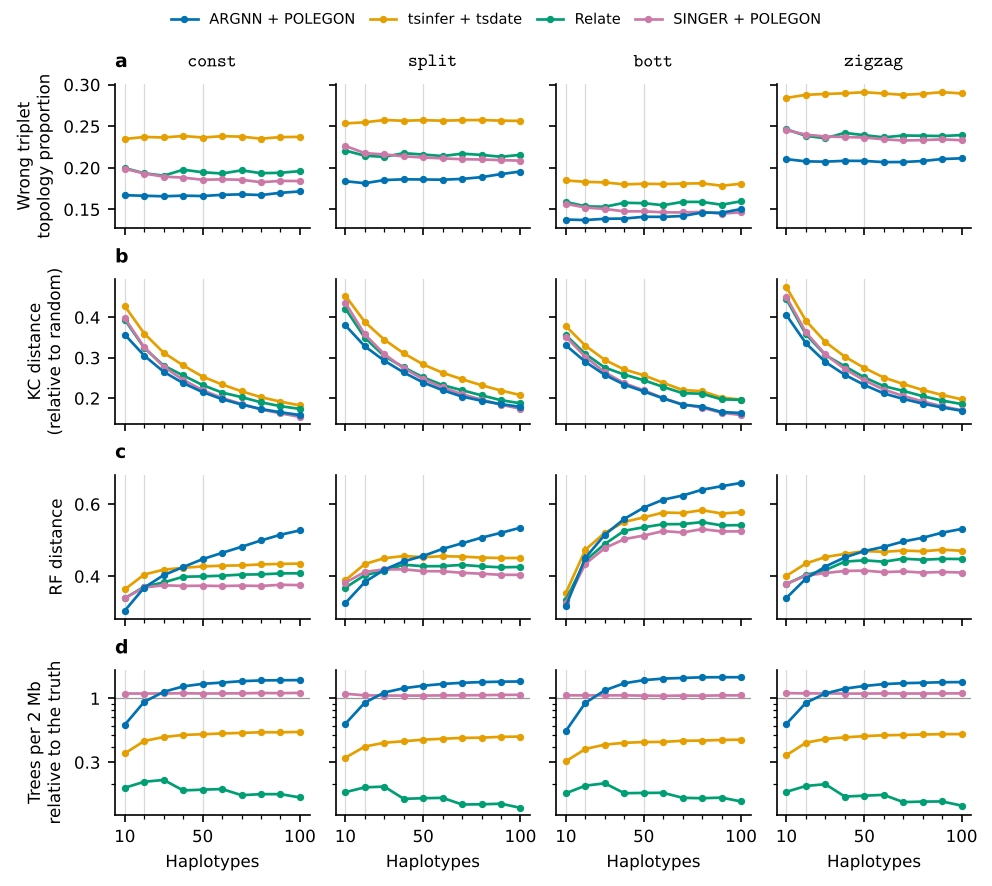

In [ ]:
topology_values = {q: metric_values(q, list(MAIN_METHODS)) for q in TOPOLOGY_QUANTITIES}
figure, axes = plt.subplots(
    len(TOPOLOGY_QUANTITIES),
    len(TRAINING_MODELS),
    figsize=(FIGURE_WIDTH, 5.8),
    sharex=True,
    sharey="row",
    layout="constrained",
)
for row, quantity in enumerate(TOPOLOGY_QUANTITIES):
    for column, model in enumerate(TRAINING_MODELS):
        axis = axes[row, column]
        part_df = topology_values[quantity]
        summary_df = mean_ci(
            part_df[part_df["model"] == model], ["configuration", "size"]
        )
        if quantity == "trees":
            finish_trees_axis(axis)
        draw_lines(axis, summary_df, MAIN_METHODS)
        if row == 0:
            # The model of each column, in cmtt10, above the top row.
            axis.annotate(
                MODEL_LABEL[model],
                (0.5, 1),
                xycoords="axes fraction",
                xytext=(0, 6),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9,
                math_fontfamily="cm",
            )
        if row == len(TOPOLOGY_QUANTITIES) - 1:
            axis.set_xlabel("Haplotypes")
    # One letter per metric, above the first panel of its row.
    style_panel(axes[row, 0], "abcd"[row])
    axes[row, 0].set_ylabel(METRIC_LABEL[quantity])
add_legend(figure, list(MAIN_METHODS))
save(figure, "benchmark_topology")
plt.show()

## Figure 2: pairwise coalescence times on `ooa`

a to d: the joint distribution of simulated and inferred pairwise TMRCAs (generations) on `ooa` at 50 haplotypes, as counts of pairs and positions in each bin over the 100 replicates, with the mean $\bar{\rho}$ over the replicates, as in deng2025robust (Fig. 2a and 2b). e to g: $\bar{\rho}$, RMSLE, and bias of log pairwise TMRCA on `ooa` against the number of haplotypes (mean and 95% confidence interval over 100 replicates per size).

written: figures/benchmark_dating.pdf


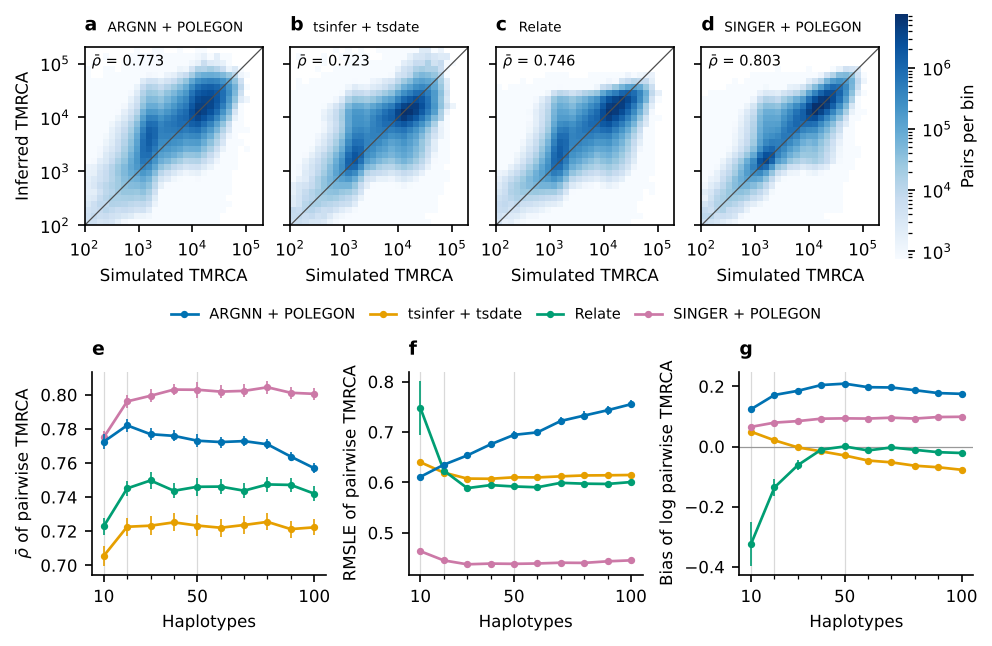

In [ ]:
JOINT_MODEL = "ooa"
JOINT_SIZE = 50
ooa_rho_df = mean_ci(
    metric_values("rho_bar", list(MAIN_METHODS)).query("model == @JOINT_MODEL"),
    ["configuration", "size"],
).set_index(["configuration", "size"])
# The bins 1 to 29 of TAU, from 100 to 200,000 generations, on a log scale.
edges = np.log10(TAU[1:31])
histograms = {
    c: joint_histogram(pooled_df, c, JOINT_SIZE, JOINT_MODEL)[1:30, 1:30]
    for c in MAIN_METHODS
}
# One color scale for the four methods, over four orders of magnitude.
largest = max(counts.max() for counts in histograms.values())
figure = plt.figure(figsize=(FIGURE_WIDTH, 4.4), layout="constrained")
# The joint distributions, a thin row for the legend, and the lines it describes.
grid = figure.add_gridspec(3, 1, height_ratios=[1.05, 0.08, 1])
top_row = grid[0].subgridspec(1, len(MAIN_METHODS))
bottom_row = grid[2].subgridspec(1, 3)
joint_axes = []
for column, (configuration, label) in enumerate(MAIN_METHODS.items()):
    axis = figure.add_subplot(top_row[column])
    joint_axes.append(axis)
    image = axis.pcolormesh(
        edges,
        edges,
        np.ma.masked_equal(histograms[configuration].T, 0),
        cmap="Blues",
        norm=LogNorm(largest * 1e-4, largest),
        rasterized=True,
    )
    axis.plot(edges[[0, -1]], edges[[0, -1]], color="0.3", linewidth=0.6)
    rho = ooa_rho_df.loc[(configuration, JOINT_SIZE)]
    axis.text(
        0.04,
        0.96,
        r"$\bar{\rho}$ = " + f"{rho['mean']:.3f}",
        transform=axis.transAxes,
        va="top",
        fontsize=7,
    )
    # A full frame around each joint distribution.
    axis.spines["top"].set_visible(True)
    axis.spines["right"].set_visible(True)
    axis.set_xticks([2, 3, 4, 5], ["$10^2$", "$10^3$", "$10^4$", "$10^5$"])
    axis.set_yticks(
        [2, 3, 4, 5], ["$10^2$", "$10^3$", "$10^4$", "$10^5$"] if column == 0 else []
    )
    axis.set_xlabel("Simulated TMRCA")
    if column == 0:
        axis.set_ylabel("Inferred TMRCA")
    axis.set_aspect("equal")
    style_panel(axis, "abcd"[column], label, title_size=6.5)
colorbar = figure.colorbar(image, ax=joint_axes, shrink=0.8, pad=0.02)
colorbar.set_label("Pairs per bin")
colorbar.outline.set_visible(False)
for column, quantity in enumerate(["rho_bar", "RMSLE", "bias"]):
    axis = figure.add_subplot(bottom_row[column])
    summary_df = mean_ci(
        metric_values(quantity, list(MAIN_METHODS)).query("model == @JOINT_MODEL"),
        ["configuration", "size"],
    )
    draw_lines(axis, summary_df, MAIN_METHODS)
    if quantity == "bias":
        axis.axhline(0, color="0.6", linewidth=0.6, zorder=0)
    axis.set_ylabel(METRIC_LABEL[quantity])
    axis.set_xlabel("Haplotypes")
    style_panel(axis, "efg"[column])
# The legend between the joint distributions and the lines, in an axis with nothing else.
legend_axis = figure.add_subplot(grid[1])
legend_axis.axis("off")
legend_axis.legend(
    handles=[
        Line2D([], [], color=COLOR[c], marker="o", linewidth=1.3, label=label)
        for c, label in MAIN_METHODS.items()
    ],
    loc="center",
    ncol=len(MAIN_METHODS),
    fontsize=7,
    columnspacing=1.0,
    handlelength=1.8,
    frameon=False,
)
save(figure, "benchmark_dating")
plt.show()

## Figure 3: coverage

The share of simulated pairwise TMRCAs inside the central 90% interval of their posterior, for each demographic model and size (mean over 100 replicates). Dashed line: the nominal level, 0.9.

written: figures/benchmark_coverage.pdf


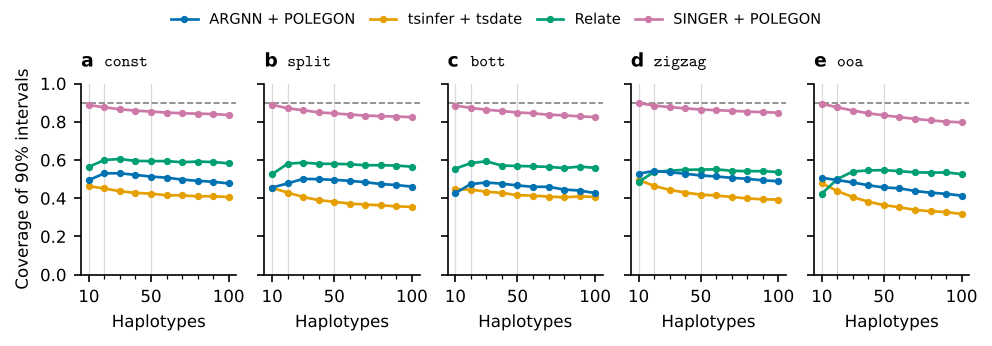

In [15]:
coverage_values_df = metric_values("coverage_90", list(MAIN_METHODS))
figure, axes = plt.subplots(
    1, len(MODELS), figsize=(FIGURE_WIDTH, 2.2), sharey=True, layout="constrained"
)
for axis, model, letter in zip(axes, MODELS, "abcde"):
    summary_df = mean_ci(
        coverage_values_df[coverage_values_df["model"] == model],
        ["configuration", "size"],
    )
    draw_lines(axis, summary_df, MAIN_METHODS, errors=False)
    axis.axhline(0.9, color="0.5", linewidth=0.8, linestyle="--", zorder=0)
    axis.set_ylim(0, 1)
    axis.set_xlabel("Haplotypes")
    style_panel(axis, letter, MODEL_LABEL[model])
axes[0].set_ylabel("Coverage of 90% intervals")
add_legend(figure, list(MAIN_METHODS))
save(figure, "benchmark_coverage")
plt.show()

## Figure 4: the held-out demography `ooa`

On `ooa`, never seen in training, with the checkpoint fine-tuned on `ooa` (mean and 95% confidence interval over 100 replicates per size). a to d: the topology metrics of Figure 1. e to g: Spearman correlation, RMSLE, and bias of mutation ages, whose age is the midpoint of their edge. h: the L2 distance between the inferred and simulated pairwise coalescence rates.

written: figures/benchmark_ooa.pdf


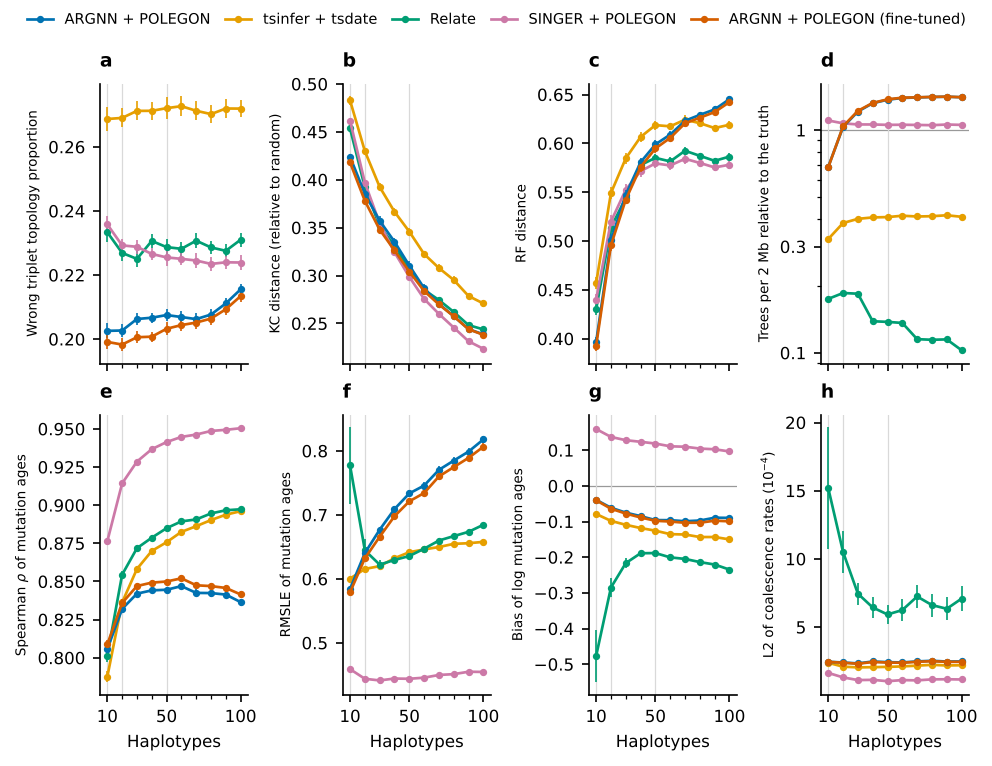

In [16]:
OOA_QUANTITIES = ["WT", "KC", "RF", "trees", "rho_a", "RMSLE_a", "bias_a", "L2"]
# 1-line labels, so each label reads along its whole axis.
OOA_LABELS = {q: label.replace("\n", " ") for q, label in METRIC_LABEL.items()} | {
    "rho_a": "Spearman $\\rho$ of mutation ages",
    "RMSLE_a": "RMSLE of mutation ages",
    "bias_a": "Bias of log mutation ages",
    "L2": "L2 of coalescence rates ($10^{-4}$)",
}
ooa_configurations = list(MAIN_METHODS) + list(FINETUNED)
figure, axes = plt.subplots(
    2, 4, figsize=(FIGURE_WIDTH, 5.0), sharex=True, layout="constrained"
)
for axis, quantity, letter in zip(axes.flat, OOA_QUANTITIES, "abcdefgh"):
    summary_df = mean_ci(
        metric_values(quantity, ooa_configurations).query("model == 'ooa'"),
        ["configuration", "size"],
    )
    if quantity == "trees":
        finish_trees_axis(axis)
    if quantity == "bias_a":
        axis.axhline(0, color="0.6", linewidth=0.6, zorder=0)
    draw_lines(axis, summary_df, MAIN_METHODS | FINETUNED)
    axis.set_ylabel(OOA_LABELS[quantity], fontsize=6.5)
    style_panel(axis, letter)
for axis in axes[1]:
    axis.set_xlabel("Haplotypes")
add_legend(figure, ooa_configurations)
save(figure, "benchmark_ooa")
plt.show()

## Figure 5: run time

Minutes per 2 Mb data set on 1 CPU core, mean and 95% confidence interval over the 100 replicates of each model and size. Relate includes EstimatePopulationSize and 100 draws of SampleBranchLengths.

written: figures/benchmark_run_time.pdf


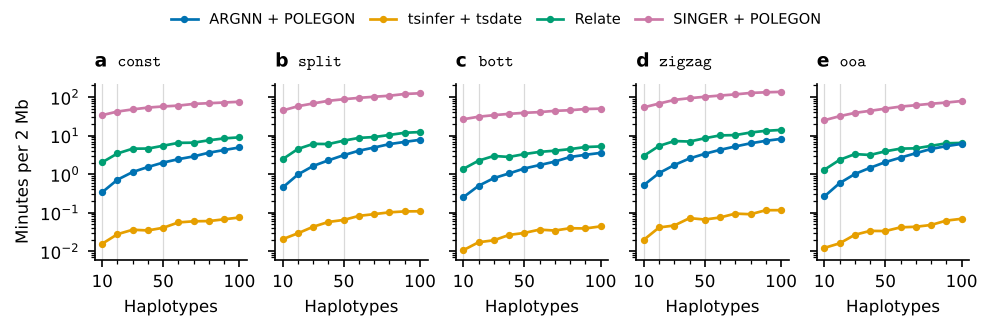

In [17]:
figure, axes = plt.subplots(
    1, len(MODELS), figsize=(FIGURE_WIDTH, 2.1), sharey=True, layout="constrained"
)
for axis, model, letter in zip(axes, MODELS, "abcde"):
    summary_df = mean_ci(
        minutes_df[
            (minutes_df["model"] == model)
            & minutes_df["configuration"].isin(MAIN_METHODS)
        ],
        ["configuration", "size"],
    )
    draw_lines(axis, summary_df, MAIN_METHODS)
    axis.set_yscale("log")
    axis.set_xlabel("Haplotypes")
    style_panel(axis, letter, MODEL_LABEL[model])
axes[0].set_ylabel("Minutes per 2 Mb")
add_legend(figure, list(MAIN_METHODS))
save(figure, "benchmark_run_time")
plt.show()

## Supplementary figures: every metric by model and size

One figure per metric, in the layout of the run-time figure: mean and 95% confidence interval over the 100 replicates of each model and size, for every method, ARGNN dated by both daters, the checkpoint fine-tuned on `ooa` (`ooa` only), and, for the dating metrics, the simulated topology dated by each dater.

In [18]:
for quantity in TOPOLOGY_QUANTITIES + DATING_QUANTITIES:
    configurations = list(METHODS) + list(FINETUNED) + list(REFERENCES)
    values_df = metric_values(quantity, configurations)
    figure, axes = plt.subplots(
        1, len(MODELS), figsize=(FIGURE_WIDTH, 2.3), sharey=True, layout="constrained"
    )
    for axis, model, letter in zip(axes, MODELS, "abcde"):
        summary_df = mean_ci(
            values_df[values_df["model"] == model], ["configuration", "size"]
        )
        if quantity == "trees":
            finish_trees_axis(axis)
        if quantity.startswith("bias"):
            axis.axhline(0, color="0.6", linewidth=0.6, zorder=0)
        if quantity == "coverage_90":
            axis.axhline(
                DRAWS_TARGET, color="0.5", linewidth=0.6, linestyle="--", zorder=0
            )
            axis.axhline(0.9, color="0.5", linewidth=0.6, linestyle=":", zorder=0)
        draw_lines(axis, summary_df, METHODS | FINETUNED | REFERENCES)
        axis.set_xlabel("Haplotypes")
        style_panel(axis, letter, MODEL_LABEL[model])
    axes[0].set_ylabel(METRIC_LABEL[quantity])
    add_legend(figure, configurations, ncol=4)
    save(figure, f"supplement_{quantity}")
    plt.close(figure)

written: figures/supplement_WT.pdf


written: figures/supplement_KC.pdf


written: figures/supplement_RF.pdf


written: figures/supplement_trees.pdf


written: figures/supplement_RMSLE.pdf


written: figures/supplement_bias.pdf


... (2 outputs left out)

written: figures/supplement_L2.pdf


written: figures/supplement_RMSLE_a.pdf


written: figures/supplement_bias_a.pdf


written: figures/supplement_rho_a.pdf


## Supplementary figure: bias by simulated time

The bias of log pairwise TMRCA in each bin of the simulated time (generations) at 100 haplotypes, for each model, with the simulated topology dated by POLEGON, whose bias is that of the dating alone. Bins that hold fewer than 0.2% of the pairs are left out.

written: figures/supplement_bias_by_time.pdf


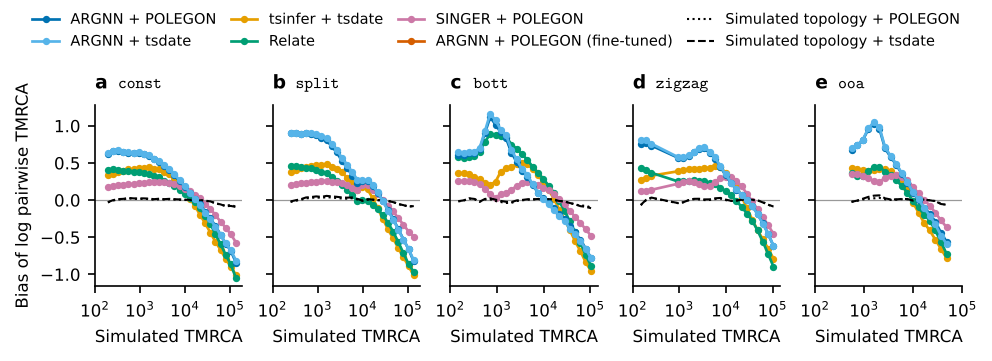

In [19]:
def draw_bias_by_time(axis, bias_by_time_df, configurations):
    """One line per configuration: the bias of log pairwise TMRCA in each bin of the simulated time that holds at
    least 0.2% of the pairs."""
    # The midpoints of the bins 1 to 29 of TAU, on a log scale.
    middles = np.log10(np.sqrt(TAU[1:30] * TAU[2:31]))
    for configuration in configurations:
        part_df = bias_by_time_df[
            (bias_by_time_df["configuration"] == configuration)
            & (bias_by_time_df["share"] >= 0.002)
            & bias_by_time_df["b"].between(1, 29)
        ].sort_values("b")
        axis.plot(
            middles[part_df["b"] - 1],
            part_df["bias"],
            color=COLOR[configuration],
            linestyle=LINESTYLE.get(configuration, "-"),
            linewidth=1.0 if configuration in REFERENCES else 1.3,
            marker="" if configuration in REFERENCES else "o",
            zorder=3 if configuration.startswith("arggnn") else 2,
        )
    axis.axhline(0, color="0.6", linewidth=0.6, zorder=0)
    axis.set_xticks([2, 3, 4, 5], ["$10^2$", "$10^3$", "$10^4$", "$10^5$"])


BIAS_SIZE = 100
bias_by_time_df = errors_by_time(pooled_df, [BIAS_SIZE], by_model=True)
figure, axes = plt.subplots(
    1, len(MODELS), figsize=(FIGURE_WIDTH, 2.3), sharey=True, layout="constrained"
)
for axis, model, letter in zip(axes, MODELS, "abcde"):
    draw_bias_by_time(
        axis,
        bias_by_time_df[bias_by_time_df["model"] == model],
        list(METHODS) + list(FINETUNED) + list(REFERENCES),
    )
    axis.set_xlabel("Simulated TMRCA")
    style_panel(axis, letter, MODEL_LABEL[model])
axes[0].set_ylabel("Bias of log pairwise TMRCA")
add_legend(figure, list(METHODS) + list(FINETUNED) + list(REFERENCES), ncol=4)
save(figure, "supplement_bias_by_time")
plt.show()

## Supplementary figure: coalescence rates

The effective population size $N_e(t) = 1/(2\lambda(t))$ from the pairwise coalescence rates at 50 haplotypes, mean over the 100 replicates of each model, against the simulated truth.

written: figures/benchmark_coalescence_rates.pdf


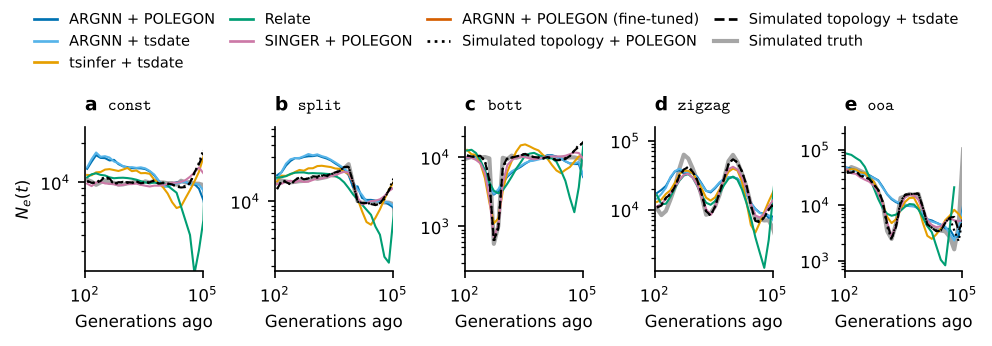

In [20]:
RATES_SIZE = 50
RATES_CONFIGURATIONS = list(METHODS) + list(FINETUNED) + list(REFERENCES)
rates_df = coalescence_rates(
    pooled_df, ["simulation"] + RATES_CONFIGURATIONS, RATES_SIZE
)
figure, axes = plt.subplots(
    1, len(MODELS), figsize=(FIGURE_WIDTH, 2.2), layout="constrained"
)
for axis, model, letter in zip(axes, MODELS, "abcde"):
    for configuration in ["simulation"] + RATES_CONFIGURATIONS:
        part_df = rates_df[
            (rates_df["model"] == model)
            & (rates_df["configuration"] == configuration)
            & rates_df["index"].between(1, 28)
        ].sort_values("index")
        part_df = part_df[part_df["lambda"] > 0]
        bins = part_df["index"].astype(int)
        times = np.sqrt(TAU[bins] * TAU[bins + 1])
        if configuration == "simulation":
            simulated_ne = 1 / (2 * part_df["lambda"])
        axis.plot(
            times,
            1 / (2 * part_df["lambda"]),
            color="black" if configuration == "simulation" else COLOR[configuration],
            linestyle=LINESTYLE.get(configuration, "-"),
            linewidth=2.0 if configuration == "simulation" else 1.0,
            alpha=0.35 if configuration == "simulation" else 1.0,
            zorder=1 if configuration == "simulation" else 2,
        )
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlim(1e2, 1e5)
    # The range of the simulated curve, widened 2.5 times, so a wild estimate does not flatten the others.
    axis.set_ylim(simulated_ne.min() / 2.5, simulated_ne.max() * 2.5)
    axis.yaxis.set_minor_formatter(NullFormatter())
    axis.set_xlabel("Generations ago")
    style_panel(axis, letter, MODEL_LABEL[model])
axes[0].set_ylabel("$N_e(t)$")
handles = [
    Line2D(
        [],
        [],
        color=COLOR[c],
        linestyle=LINESTYLE.get(c, "-"),
        label=(METHODS | FINETUNED | REFERENCES)[c],
    )
    for c in RATES_CONFIGURATIONS
]
handles.append(
    Line2D([], [], color="black", alpha=0.35, linewidth=2.0, label="Simulated truth")
)
figure.legend(
    handles=handles,
    loc="outside upper center",
    ncol=4,
    fontsize=7,
    columnspacing=1.0,
    handlelength=1.6,
)
save(figure, "benchmark_coalescence_rates")
plt.show()

## Supplementary figure: SINGER's MCMC trace

The two diagnostics of SINGER's chain that deng2025robust uses (Supp D.4, Supp Fig. 10): the mean squared error of the diversity fit in 10 kb windows and the number of incompatible sites, for each of the 600 samples of the chain (one every 20 iterations), relative to their mean over the 100 kept samples, averaged over the 100 replicates of each model and size. The dashed line marks the end of the burn-in, at 10,000 iterations.

written: figures/singer_mcmc_trace.pdf


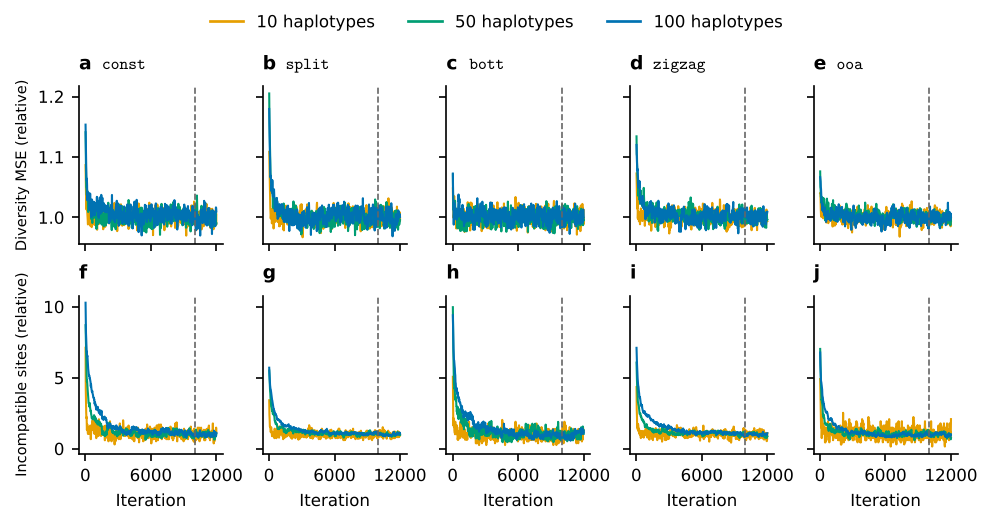

In [21]:
TRACE_SIZES = {10: "#E69F00", 50: "#009E73", 100: "#0072B2"}
trace_df = pooled_df[
    pooled_df["quantity"].isin(["diversity_mse", "incompatible_sites"])
    & (pooled_df["configuration"] == "singer_polegon")
].copy()
trace_df["mean"] = trace_df["sum"] / trace_df["count"]
trace_df["sample"] = trace_df["index"].astype(int)
trace_df["iteration"] = 20 * (trace_df["sample"] + 1)
kept_mean = (
    trace_df[trace_df["sample"] >= 500]
    .groupby(["model", "size", "quantity"])["mean"]
    .mean()
    .rename("kept_mean")
)
trace_df = trace_df.join(kept_mean, on=["model", "size", "quantity"])
trace_df["relative"] = trace_df["mean"] / trace_df["kept_mean"]
figure, axes = plt.subplots(
    2,
    len(MODELS),
    figsize=(FIGURE_WIDTH, 3.4),
    sharex=True,
    sharey="row",
    layout="constrained",
)
# 1-line labels, so the labels of the 2 rows cannot overlap; the caption says relative to what.
TRACE_LABELS = {
    "diversity_mse": "Diversity MSE (relative)",
    "incompatible_sites": "Incompatible sites (relative)",
}
for row, (quantity, label) in enumerate(TRACE_LABELS.items()):
    for column, model in enumerate(MODELS):
        axis = axes[row, column]
        for size, color in TRACE_SIZES.items():
            part_df = trace_df[
                (trace_df["quantity"] == quantity)
                & (trace_df["model"] == model)
                & (trace_df["size"] == size)
            ].sort_values("iteration")
            axis.plot(
                part_df["iteration"], part_df["relative"], color=color, linewidth=1.0
            )
        # The end of the burn-in.
        axis.axvline(10_000, color="0.4", linewidth=0.8, linestyle="--")
        if row == 1:
            axis.set_xlabel("Iteration")
        if column == 0:
            axis.set_ylabel(label, fontsize=7)
        style_panel(
            axis,
            "abcdefghij"[row * len(MODELS) + column],
            MODEL_LABEL[model] if row == 0 else None,
        )
axes[0, 0].set_xticks([0, 6000, 12000])
figure.align_ylabels(axes[:, 0])
handles = [
    Line2D([], [], color=color, label=f"{size} haplotypes")
    for size, color in TRACE_SIZES.items()
]
figure.legend(handles=handles, loc="outside upper center", ncol=3)
save(figure, "singer_mcmc_trace")
plt.show()